In [15]:
try:
    import os
    import random
    import numpy as np
    import matplotlib.pyplot as plt
    import networkx as nx
except Exception as e:
    %pip install matplotlib
    import matplotlib.pyplot as plt
    %pip install networkx
    import networkx as nx

    

In [16]:
def generar_matriz_aleatoria(N, densidad=0.3):
    matriz = np.zeros((N, N), dtype=int)
    for i in range(N):
        for j in range(i + 1, N):
            if random.random() < densidad:
                matriz[i][j] = 1
                matriz[j][i] = 1
    return matriz


def cargar_matriz_desde_archivo(ruta_archivo):
    if not os.path.exists(ruta_archivo):
        raise FileNotFoundError(f"El archivo {ruta_archivo} no existe.")

    matriz = np.loadtxt(ruta_archivo, dtype=int)
    if matriz.shape[0] != matriz.shape[1]:
        raise ValueError("La matriz debe ser cuadrada (NxN).")
    if not np.allclose(matriz, matriz.T):
        raise ValueError("La matriz de adyacencia debe ser simétrica.")

    return matriz


In [17]:
class CSPGraphColoring:

    def __init__(self, matriz_adyacencia, num_colores):
        self.adj = matriz_adyacencia
        self.N = len(matriz_adyacencia)
        self.K = num_colores
        self.dominios = {i: list(range(self.K)) for i in range(self.N)}
        self.asignacion = {}
        self.grados = [sum(self.adj[i]) for i in range(self.N)]

    def seleccionar_variable_DO(self, no_asignados):
        return max(no_asignados, key=lambda v: self.grados[v])

    def forward_checking(self, v, color):
        recortes = []
        vecinos = [u for u in range(self.N) if self.adj[v][u] == 1]

        for u in vecinos:
            if u not in self.asignacion:
                if color in self.dominios[u]:
                    self.dominios[u].remove(color)
                    recortes.append((u, color))

                    if len(self.dominios[u]) == 0:
                        return False, recortes

        return True, recortes

    def restaurar_dominios(self, recortes):
        for u, color in recortes:
            self.dominios[u].append(color)

    def resolver(self):
        no_asignados = [i for i in range(self.N) if i not in self.asignacion]

        if not no_asignados:
            return True

        var = self.seleccionar_variable_DO(no_asignados)
        for color in list(self.dominios[var]):
            self.asignacion[var] = color
            exito, recortes = self.forward_checking(var, color)
            if exito:
                if self.resolver():
                    return True

            del self.asignacion[var]
            self.restaurar_dominios(recortes)

        return False

In [31]:
def visualizar_grafo(matriz_adyacencia, asignacion_colores):
    N = len(matriz_adyacencia)
    G = nx.Graph()

    # Agregar nodos y aristas
    for i in range(N):
        G.add_node(i)

    for i in range(N):
        for j in range(i + 1, N):
            if matriz_adyacencia[i][j] == 1:
                G.add_edge(i, j)

    paleta = [
        "red",
        "blue",
        "green",
        "yellow",
        "orange",
        "purple",
        "cyan",
        "magenta",
        "lime",
        "pink",
    ]

    colores_nodos = [
        paleta[asignacion_colores[i] % len(paleta)] for i in range(N)
    ]

    plt.figure(figsize=(9, 7))

    # Layout optimizado: mayor valor de 'k' para separar nodos y estirar aristas
    pos = nx.spring_layout(G, k=1.8 / (N**0.5), iterations=100, seed=30)

    nx.draw_networkx_edges(
        G,
        pos,
        width=1.8,
        alpha=0.4,  # Transparente para distinguir cuando pasan por detrás
        edge_color="gray",
    )

    # Dibujar nodos encima
    nx.draw_networkx_nodes(
        G,
        pos,
        node_color=colores_nodos,
        node_size=850,  
        edgecolors="black",
        linewidths=2.0,
    )

    nx.draw_networkx_labels(
        G, pos, font_size=11, font_color="white", font_weight="bold"
    )

    plt.title(f"Solución de Coloreado de Grafo (N = {N})", fontsize=14)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

Solución encontrada con 3 colores
Asignación de colores por nodo: {9: 0, 1: 1, 3: 1, 6: 0, 8: 0, 0: 2, 2: 2, 5: 1, 7: 1, 11: 1, 4: 0, 10: 2}


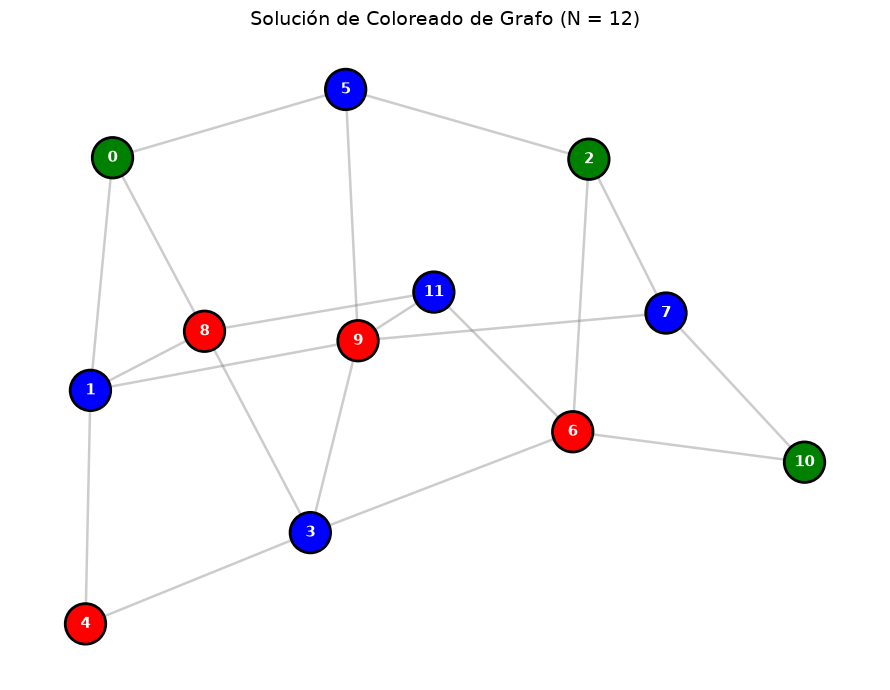

In [32]:
N = 12  # Número de nodos
num_colores = 3  # Número máximo de colores permitidos 
MODO = "aleatorio"  # Opciones: "aleatorio" o "archivo"

if MODO == "aleatorio":
    matriz = generar_matriz_aleatoria(N, densidad=0.35)
else:
    matriz = cargar_matriz_desde_archivo("matriz_ejemplo.txt")

csp = CSPGraphColoring(matriz, num_colores)

if csp.resolver():
    print(f"Solución encontrada con {num_colores} colores")
    print("Asignación de colores por nodo:", csp.asignacion)
    visualizar_grafo(matriz, csp.asignacion)
else:
    print(f"No existe una solución válida para este grafo con {num_colores} colores.")